
# Setup


- **Environment:** Python 3.12 with `numpy==2.4.6`, `pandas==3.0.3`, `scipy==1.15.3`, `statsmodels==0.14.6`, `matplotlib==3.11.0`, `ipykernel`, `nbformat`, and `nbclient` (preinstalled in the repo's `.venv`). Select that kernel, start at the repo root, and **Run All**.
- **Default mode (`A04_MODE=replay`):** Offline analysis-only replay. Verifies checksums on the bundled data and genuine capture, then regenerates all scores and figures without calling Ollama or refitting models.
- **Live mode (`A04_MODE=live`):** Runs fresh local inference against Ollama (`qwen3.5:9b-q8_0`, ~10.4 GB). Never substitutes cached responses on failure, and requires an author audit (`audit.json`) before scoring. See [the launch guide](docs/module-4-implementation.md).

In [1]:
# Standard library
import gzip
import hashlib
import importlib.metadata
import json
import os
import platform
import textwrap
import time
import urllib.request
import warnings
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

# Third party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import norm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.statespace.structural import UnobservedComponents

`statsmodels` provides our state-space (`UnobservedComponents`), `SARIMAX`, and Ljung–Box residual diagnostic tools; `scipy.stats.norm` supplies Gaussian quantiles for prediction intervals. Model calls use Python's built-in `urllib.request` against Ollama's local HTTP API—no external agent framework required.

In [2]:
class CFG:
    episode_number = 4
    asset_prefix = f"atsf{episode_number:02d}_"
    root = Path.cwd()
    data_dir = root / "data/module04"
    evidence_dir = root / "examples/module04"
    graph_dir = root / "graphs"
    timezone = "Europe/Amsterdam"
    execution_started_at = datetime.now(ZoneInfo(timezone)).isoformat()
    mode = os.environ.get("A04_MODE", "replay")
    run_id = os.environ.get("A04_RUN_ID", datetime.now(ZoneInfo(timezone)).strftime("live-%Y%m%dT%H%M%S%f"))
    export_id = datetime.now(ZoneInfo(timezone)).strftime("export-%Y%m%dT%H%M%S%f")
    export_dir = evidence_dir / "exports" / export_id
    endpoint = "http://127.0.0.1:11434"
    model = "qwen3.5:9b-q8_0"
    temperature, seed, num_ctx, num_predict = 0, 42, 16384, 3000
    keep_alive = "20m"
    max_requests, max_tools, request_seconds, workflow_seconds = 2, 16, 90, 900
    max_input_characters, reason_words = 24000, 60
    stores = list(range(1, 11))
    prefix_n, horizon, origins = 1736, 90, [1466, 1556, 1646]
    diagnostic_window, diagnostic_lag, diagnostic_alpha = 364, 28, .05
    annual_period, harmonics, maxiter, alpha = 365.25, 3, 500, .2
    method_order = ["seasonal_naive", "trend", "bsm", "sarimax"]
    figure_width, figure_height, dpi, table_font = 9.5, 6.5, 200, 12
    core_sha256 = "053484732c62ddde1fb6f241f40517fd35e9dcd59ba349f75cc3bf5a164e9904"
    assets = []

np.random.seed(CFG.seed)
plt.style.use("seaborn-v0_8")
plt.rcParams.update({"figure.figsize": (CFG.figure_width, CFG.figure_height), "font.size": 12})

`CFG` centralizes all experiment constants:
- **Execution & Ollama:** `mode` (`replay` vs. `live`), `qwen3.5:9b-q8_0` at `temperature=0` and `seed=42`, with a **2-request** cap (initial plan + at most 1 revision), **16-tool** cap, **90s** per-request timeout, and **900s** workflow admission deadline (checked before each tool and fit).
- **Data & validation:** 10 stores, `prefix_n=1736` permitted days, `horizon=90`, and three expanding validation origins (`1466`, `1556`, `1646`).
- **Models & diagnostics:** `seasonal_naive`, `trend`, `bsm`, and `sarimax`, plus a 364-day Ljung–Box residual window at lag 28 (`alpha=0.05`).



# Utils

In [3]:
def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False))


def load_json(path):
    return json.loads(Path(path).read_text())


def environment_record():
    return {"python": platform.python_version(), "os": platform.platform(), "architecture": platform.machine(),
            "packages": {p: importlib.metadata.version(p) for p in
                         ("numpy", "pandas", "scipy", "statsmodels", "matplotlib", "nbclient", "nbformat", "ipykernel")},
            "numpy_backend": np.__config__.show(mode="dicts")}


def contract_settings():
    return {"episode_number": CFG.episode_number, "core_sha256": CFG.core_sha256,
            "stores": CFG.stores, "prefix_n": CFG.prefix_n, "horizon": CFG.horizon, "origins": CFG.origins,
            "diagnostic": [CFG.diagnostic_window, CFG.diagnostic_lag, CFG.diagnostic_alpha],
            "numerical": [CFG.annual_period, CFG.harmonics, CFG.maxiter, CFG.alpha], "method_order": CFG.method_order,
            "budgets": [CFG.max_requests, CFG.max_tools, CFG.request_seconds, CFG.workflow_seconds, CFG.max_input_characters],
            "model": [CFG.model, CFG.temperature, CFG.seed, CFG.num_ctx, CFG.num_predict, CFG.keep_alive],
            "schemas": [plan_schema(False), plan_schema(True)], "prompts": [system_prompt(False), system_prompt(True)]}


def load_panel():
    manifest = load_json(CFG.data_dir / "manifest.json")
    raw_bytes = gzip.decompress((CFG.data_dir / "retail.csv.gz").read_bytes())
    if hashlib.sha256(raw_bytes).hexdigest() != manifest["raw_sha256"]:
        raise ValueError("Retail source checksum changed; rebuild provenance explicitly.")
    panel = pd.read_csv(CFG.data_dir / "store_daily.csv", parse_dates=["date"])
    if file_hash(CFG.data_dir / "store_daily.csv") != manifest["aggregate_sha256"]:
        raise ValueError("Store aggregation checksum changed.")
    assert panel.shape == (18260, 3)
    assert not panel.duplicated(["store", "date"]).any()
    assert not panel.isna().any().any()
    assert np.isfinite(panel.sales).all() and (panel.sales > 0).all()
    assert sorted(panel.store.unique().tolist()) == CFG.stores
    calendar = pd.date_range("2013-01-01", periods=1826, freq="D")
    for _, group in panel.groupby("store", sort=True):
        assert pd.DatetimeIndex(group.date).equals(calendar)
    return panel, manifest


def permitted_series(panel):
    # This function is the only gateway from the full panel to the executor.
    return {str(store): group.sort_values("date").iloc[:CFG.prefix_n].sales.to_numpy(float)
            for store, group in panel.groupby("store", sort=True)}


def profile_series(series):
    return {store: {"n": len(y), "mean": float(np.mean(y)),
                    "minimum": float(np.min(y)), "maximum": float(np.max(y)),
                    "acf7": float(acf(y, nlags=7, fft=True)[7])}
            for store, y in series.items()}


def fourier(days):
    # Absolute days since 2013-01-01, including when constructing future features.
    days = np.asarray(days, dtype=float)
    return np.column_stack([f(2 * np.pi * k * days / CFG.annual_period)
                            for k in range(1, CFG.harmonics + 1)
                            for f in (np.sin, np.cos)])


class AdmissionExpired(RuntimeError):
    pass


def admit(deadline):
    if deadline is not None and time.monotonic() >= deadline:
        raise AdmissionExpired("No new fit/tool admitted after workflow deadline.")


def gaussian_output(mu, variance, transform):
    mu, variance = np.asarray(mu), np.asarray(variance)
    if not np.isfinite(mu).all() or not np.isfinite(variance).all() or (variance < 0).any():
        raise ValueError("Invalid predictive mean or variance")
    z = norm.ppf(1 - CFG.alpha / 2)
    low, high = mu - z * np.sqrt(variance), mu + z * np.sqrt(variance)
    mean = mu
    if transform == "log":
        mean, low, high = np.exp(mu + variance / 2), np.exp(low), np.exp(high)
    if not all(np.isfinite(v).all() for v in (mean, low, high)):
        raise ValueError("Nonfinite back-transformed forecast")
    return {"mean": mean.tolist(), "lower": low.tolist(), "upper": high.tolist()}


def fit_forecast(y, method, transform, work, deadline=None):
    admit(deadline)
    started = time.monotonic()
    event = {"method": method, "transform": transform, "n": len(y),
             "status": "started", "input_sha256": digest(np.asarray(y).tolist())}
    work["fits"].append(event)
    try:
        endog = np.log(y) if transform == "log" else np.asarray(y)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            if method == "trend":
                model = UnobservedComponents(endog, level="local linear deterministic trend")
            elif method == "bsm":
                model = UnobservedComponents(
                    endog, level="local linear trend", seasonal=7,
                    freq_seasonal=[{"period": CFG.annual_period, "harmonics": CFG.harmonics}])
            elif method == "sarimax":
                model = SARIMAX(endog, exog=fourier(np.arange(len(y))),
                                order=(1, 1, 1), seasonal_order=(1, 1, 1, 7))
            else:
                raise ValueError("Unknown numerical method")
            fitted = model.fit(disp=False, method="lbfgs", maxiter=CFG.maxiter)
        event["warnings"] = [str(w.message) for w in caught]
        event["converged"] = bool(fitted.mle_retvals.get("converged", False))
        if not event["converged"]:
            raise ValueError("Optimizer did not converge")
        kwargs = {"exog": fourier(np.arange(len(y), len(y) + CFG.horizon))} if method == "sarimax" else {}
        fc = fitted.get_forecast(CFG.horizon, **kwargs)
        mu, variance = np.asarray(fc.predicted_mean), np.asarray(fc.var_pred_mean)
        gaussian_output(mu, variance, transform)  # finite-value check; not yet delivered
        innovations = np.asarray(fitted.filter_results.standardized_forecasts_error[0])
        burn = max(int(fitted.loglikelihood_burn), int(fitted.model.k_states))
        innovations = innovations[burn:][-CFG.diagnostic_window:]
        if len(innovations) != CFG.diagnostic_window or not np.isfinite(innovations).all():
            raise ValueError("Insufficient finite innovations after initialization")
        event["status"] = "completed"
        return {"mu": mu.tolist(), "variance": variance.tolist(),
                "innovations": innovations.tolist(), "parameters": np.asarray(fitted.params).tolist()}
    except Exception as exc:
        event["status"], event["error"] = "failed", f"{type(exc).__name__}: {exc}"
        raise
    finally:
        event["seconds"] = time.monotonic() - started


def baseline_record(y):
    folds, absolute_errors = [], []
    for origin in CFG.origins:
        pred = np.resize(y[:origin][-7:], CFG.horizon)
        error = y[origin:origin + CFG.horizon] - pred
        folds.append({"origin": origin, "rmse": float(np.sqrt(np.mean(error ** 2))),
                      "prediction": pred.tolist()})
        absolute_errors.extend(np.abs(error).tolist())
    return {"status": "eligible", "rmse": float(np.mean([f["rmse"] for f in folds])),
            "folds": folds, "mean": np.resize(y[-7:], CFG.horizon).tolist(),
            "width": float(np.quantile(absolute_errors, 1 - CFG.alpha, method="linear"))}


def candidate_record(y, method, transform, work, deadline=None):
    record = {"status": "running", "folds": [], "rmse": None}
    try:
        for origin in CFG.origins:
            fit = fit_forecast(y[:origin], method, transform, work, deadline)
            pred = np.asarray(gaussian_output(fit["mu"], fit["variance"], transform)["mean"])
            error = y[origin:origin + CFG.horizon] - pred
            record["folds"].append({"origin": origin, "rmse": float(np.sqrt(np.mean(error ** 2))),
                                    "prediction": pred.tolist()})
        record["rmse"] = float(np.mean([f["rmse"] for f in record["folds"]]))
        record["validation_complete"] = True
        # Final-origin fit uses the permitted prefix only; final outcomes are absent.
        record["current"] = fit_forecast(y, method, transform, work, deadline)
        record["status"] = "eligible"
    except Exception as exc:
        record["status"] = "not_attempted_deadline" if isinstance(exc, AdmissionExpired) else "failed"
        record["error"] = f"{type(exc).__name__}: {exc}"
        record["validation_complete"] = len(record["folds"]) == len(CFG.origins)
    return record


def monitor(record):
    if record["status"] != "eligible":
        return {"status": "unavailable", "reason": record.get("error", record["status"])}
    values = np.asarray(record["current"]["innovations"])
    test = acorr_ljungbox(values, lags=[CFG.diagnostic_lag], model_df=0, return_df=True)
    pvalue = float(test.lb_pvalue.iloc[0])
    correlation = acf(values, nlags=CFG.diagnostic_lag, fft=True)
    return {"status": "failed_check" if pvalue < CFG.diagnostic_alpha else "passed",
            "pvalue": pvalue, "acf7": float(correlation[7]), "acf28": float(correlation[28]),
            "statistic": float(test.lb_stat.iloc[0]), "n": len(values)}


def choose(catalog):
    eligible = [m for m in CFG.method_order if m in catalog and catalog[m]["status"] == "eligible"]
    if not eligible:
        return None
    return min(eligible, key=lambda m: (catalog[m]["rmse"], CFG.method_order.index(m)))


def deliver(catalog, selected, transform, controller, fallback_reason=None):
    chosen = selected
    if selected is None or catalog.get(selected, {}).get("status") != "eligible":
        chosen, fallback_reason = "seasonal_naive", fallback_reason or "selected_method_unavailable"
    rec = catalog.get(chosen)
    if rec is None or rec.get("status") != "eligible":
        return {"selected": selected, "delivered": None, "status": "missing", "controller": controller,
                "fallback": True, "reason": fallback_reason or "baseline_unavailable"}
    if chosen == "seasonal_naive":
        mean = np.asarray(rec["mean"])
        output = {"mean": mean.tolist(), "lower": (mean - rec["width"]).tolist(),
                  "upper": (mean + rec["width"]).tolist(), "interval_method": "empirical_validation_errors"}
    else:
        output = gaussian_output(rec["current"]["mu"], rec["current"]["variance"], transform)
        output["interval_method"] = "plug_in_gaussian" if transform == "identity" else "plug_in_lognormal"
    return dict(output, selected=selected, delivered=chosen, status="delivered", controller=controller,
                fallback=fallback_reason is not None, reason=fallback_reason)

Note that `candidate_record` and `monitor` measure two different things: validation RMSE scores 90-day out-of-sample forecasts, whereas `monitor` runs Ljung–Box on one-step in-sample innovations. A low p-value flags leftover structure for review—it doesn't diagnose the cause or guarantee a fix.

## Plans, model requests and contracts

Rather than letting the LLM invent arbitrary task graphs, we constrain it to a fixed two-phase DAG (`INITIAL_TOOLS` → `REVISION_TOOLS`):
1. **Initial plan (7 steps):** `check_data → transform → baseline → candidates → diagnostic → uncertainty → deliver`. The planner chooses `transform` (`identity` or `log`) and supplies a ≤60-word `reason`; `candidates` is fixed to `["trend"]` as the initial test.
2. **Revision suffix (4 steps, only if `diagnostic` fails):** `repair → diagnostic_v2 → uncertainty_v2 → deliver_v2`. The planner must keep the original `transform`, cite the exact `failed_evidence_id`, and choose `bsm`, `sarimax`, or both.

`validate_plan` enforces both the JSON schema and semantic rules (immutable cutoffs, exact dependencies, unique candidates, word-capped reason). `request_plan` calls Ollama with `think=False` and logs the exact payload, token counts, and timing. `patch_ledger` marks pending/blocked steps as `superseded` while preserving completed work and the failed diagnostic.

In [4]:
INITIAL_TOOLS = ["check_data", "transform", "baseline", "candidates", "diagnostic", "uncertainty", "deliver"]
REVISION_TOOLS = ["repair", "diagnostic_v2", "uncertainty_v2", "deliver_v2"]


def expected_steps(revision=False):
    tools = REVISION_TOOLS if revision else INITIAL_TOOLS
    return [{"id": tool, "tool": tool,
             "depends_on": [tools[i - 1]] if i else (["diagnostic"] if revision else [])}
            for i, tool in enumerate(tools)]


def plan_schema(revision=False):
    def obj(properties):
        return {"type": "object", "properties": properties, "required": list(properties), "additionalProperties": False}
    const = lambda v: {"type": "integer" if isinstance(v, int) else "number", "enum": [v]}
    fields = {
        "transform": {"type": "string", "enum": ["identity", "log"]},
        "horizon": const(CFG.horizon),
        "origins": {"type": "array", "items": {"type": "integer"}, "minItems": 3, "maxItems": 3},
        "candidates": {"type": "array", "items": {"type": "string", "enum": ["bsm", "sarimax"] if revision else ["trend"]},
                       "minItems": 1, "maxItems": 2 if revision else 1},
        "diagnostic": obj({"window": const(CFG.diagnostic_window), "lag": const(CFG.diagnostic_lag),
                           "alpha": const(CFG.diagnostic_alpha)}),
        "uncertainty": obj({"structural": {"type": "string", "enum": ["gaussian"]},
                            "baseline": {"type": "string", "enum": ["absolute_validation_errors"]},
                            "alpha": const(CFG.alpha)}),
        "steps": {"type": "array", "items": obj({"id": {"type": "string"}, "tool": {"type": "string"},
                    "depends_on": {"type": "array", "items": {"type": "string"}}}),
                  "minItems": 4 if revision else 7, "maxItems": 4 if revision else 7},
        "reason": {"type": "string"}}
    if revision:
        fields["failed_evidence_id"] = {"type": "string"}
    return obj(fields)


def validate_plan(plan, revision=False, original=None, failed_evidence=None):
    required = set(plan_schema(revision)["required"])
    if not isinstance(plan, dict) or set(plan) != required:
        raise ValueError("Plan fields do not match the contract")
    if plan["transform"] not in ("identity", "log") or plan["horizon"] != CFG.horizon or plan["origins"] != CFG.origins:
        raise ValueError("Invalid transform or changed chronological contract")
    if plan["diagnostic"] != {"window": CFG.diagnostic_window, "lag": CFG.diagnostic_lag, "alpha": CFG.diagnostic_alpha}:
        raise ValueError("Changed monitor contract")
    if plan["uncertainty"] != {"structural": "gaussian", "baseline": "absolute_validation_errors", "alpha": CFG.alpha}:
        raise ValueError("Changed uncertainty contract")
    allowed = {"bsm", "sarimax"} if revision else {"trend"}
    candidates = plan["candidates"]
    if not isinstance(candidates, list) or not candidates or len(set(candidates)) != len(candidates) or not set(candidates) <= allowed:
        raise ValueError("Invalid or duplicate candidates")
    reason = plan["reason"]
    if not isinstance(reason, str) or not 1 <= len(reason.split()) <= CFG.reason_words:
        raise ValueError("Public reason must contain 1–60 words")
    # The small allowed graph is explicit; arbitrary or cyclic task graphs are rejected.
    if plan["steps"] != expected_steps(revision):
        raise ValueError("Unknown/cyclic/missing steps or invalid prerequisites")
    if revision:
        if plan["transform"] != original["transform"]:
            raise ValueError("Revision must retain completed transformation")
        if plan["failed_evidence_id"] != failed_evidence:
            raise ValueError("Stale or missing failed-check evidence")
    return plan


def system_prompt(revision=False):
    role = "Revise the pending suffix after the recorded monitor failed." if revision else "Write the entire experiment plan before execution."
    return ("You are a forecasting experiment planner. " + role +
            " Return only the exact JSON contract. Give a brief public reason of at most 60 words, not private reasoning. "
            "The first experiment deliberately tests trend-only structure; this is an assigned teaching challenge. "
            "Code computes forecasts, checks dependencies and selects by validation RMSE. Never change cutoffs or invent measurements. "
            "Use the supplied exact required_steps, horizon, origins, diagnostic and uncertainty fields. "
            "Choose identity or log initially. After failure keep that transform and choose bsm, sarimax, or both as repair candidates. "
            "A small residual p-value signals a failed engineering check; it does not identify a cause or guarantee a repair.")


def http_json(path, payload=None, timeout=10):
    req = urllib.request.Request(CFG.endpoint + path, data=None if payload is None else canonical(payload).encode(),
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as response:
        return json.load(response)


def server_identity():
    tags = http_json("/api/tags")
    found = [m for m in tags["models"] if m["name"] == CFG.model]
    if not found:
        raise RuntimeError(f"Install explicitly with ollama pull {CFG.model}; no model/provider substitution is allowed.")
    return {"model": found[0], "server": http_json("/api/version")}


def request_plan(semantic, revision, deadline, capture, run_dir, original=None, failed_id=None):
    admit(deadline)
    if len(capture["requests"]) >= CFG.max_requests:
        raise ValueError("Shared request budget exhausted")
    if len(canonical(semantic)) > CFG.max_input_characters:
        raise ValueError("Model-visible summary exceeds predeclared size cap")
    payload = {"model": CFG.model, "messages": [{"role": "system", "content": system_prompt(revision)},
                {"role": "user", "content": canonical(semantic)}], "format": plan_schema(revision),
               "stream": False, "think": False, "keep_alive": CFG.keep_alive,
               "options": {"temperature": CFG.temperature, "seed": CFG.seed,
                           "num_ctx": CFG.num_ctx, "num_predict": CFG.num_predict}}
    attempt = {"phase": "revision" if revision else "initial", "semantic_input": semantic,
               "input_sha256": digest(semantic), "payload": payload, "status": "started"}
    capture["requests"].append(attempt)
    save_json(run_dir / "capture.partial.json", capture)
    started = time.monotonic()
    try:
        raw = http_json("/api/chat", payload, timeout=min(CFG.request_seconds, max(.01, deadline-time.monotonic())))
        attempt["raw_response"] = raw
        if raw.get("done") is not True or raw.get("done_reason") != "stop":
            raise ValueError("Provider response did not complete normally")
        plan = validate_plan(json.loads(raw["message"]["content"]), revision, original, failed_id)
        attempt["plan"], attempt["status"] = plan, "accepted"
        return plan
    except Exception as exc:
        attempt["status"], attempt["error"] = "failed", f"{type(exc).__name__}: {exc}"
        raise
    finally:
        attempt["seconds"] = time.monotonic() - started
        save_json(run_dir / "capture.partial.json", capture)


def settings_input(series, revision=False):
    return {"objective": "Forecast daily store-total demand for all ten stores; first test trend-only structure.",
            "case_order": list(series), "profile": profile_series(series), "horizon": CFG.horizon,
            "origins": CFG.origins, "diagnostic": {"window": CFG.diagnostic_window, "lag": CFG.diagnostic_lag,
                                                    "alpha": CFG.diagnostic_alpha},
            "uncertainty": {"structural": "gaussian", "baseline": "absolute_validation_errors", "alpha": CFG.alpha},
            "required_steps": expected_steps(revision),
            "candidate_catalog": {"trend": "stochastic local level + deterministic slope; no seasonality", "bsm": "local linear trend + weekly7 + annual365.25/3harmonics",
                                  "sarimax": "SARIMA(1,1,1)(1,1,1)7 + annual365.25/3harmonic regressors"},
            "permitted_input_sha256": digest({k: y.tolist() for k, y in series.items()})}


def summarize_catalog(catalogs):
    return {store: {m: {"status": r["status"], "rmse": r.get("rmse"),
                       "fold_rmse": [f["rmse"] for f in r.get("folds", [])], "sha256": digest(r)}
                    for m, r in cat.items()} for store, cat in catalogs.items()}


def initial_ledger(plan):
    return [dict(step, version=1, status="pending", output=None) for step in plan["steps"]]


def patch_ledger(ledger, revision):
    # Retain the failed event and completed prefix; supersede only the blocked suffix.
    for row in ledger:
        if row["status"] in ("pending", "blocked"):
            row["status"] = "superseded"
    ledger.extend(dict(step, version=2, status="pending", output=None) for step in revision["steps"])

Every LLM request is logged verbatim—no silent JSON repairs or provider fallbacks. If a call times out, truncates, or fails validation, it counts against the 2-request budget and fails cleanly.

## Execute, monitor and revise

`run_live` orchestrates the full experiment in five stages:
1. **Preflight:** Slices `permitted_series`, checks that the local Ollama model digest matches `protocol.json`, and starts the 900s admission clock.
2. **Initial prefix:** Requests the initial plan, populates the ledger, and runs `check_data`, `transform`, `baseline` (`seasonal_naive`), `candidates` (`trend`), and `diagnostic` across all 10 stores. It also records a counterfactual `initial_deliveries` arm (what would have been delivered with no repair).
3. **Conditional revision:** If any store fails the Ljung–Box check (`failed_check`), Python blocks `uncertainty`/`deliver`, sends a compact summary (fold RMSEs, monitor p-values, artifact hashes) to `request_plan(..., revision=True)`, patches the ledger, and runs `repair → diagnostic_v2 → uncertainty_v2 → deliver_v2`.
4. **Failure safety:** On any timeout, budget exhaustion, or planning error, Python blocks remaining steps and falls back to the best valid candidate already in `catalogs` (or `seasonal_naive`).
5. **Comparators & freeze:** After the agent finishes (and hidden from it), Python runs `fixed_bsm` (log-BSM across all 10 stores) and `seasonal_naive`, then freezes all four arms to `capture.json`, `frozen_forecasts.json`, and `freeze.json`.

In [5]:
def run_live(panel, protocol):
    series = permitted_series(panel)
    run_dir = CFG.evidence_dir / "runs" / CFG.run_id
    if run_dir.exists():
        raise FileExistsError("Refusing to overwrite an inference archive; choose a new A04_RUN_ID.")
    run_dir.mkdir(parents=True)
    identity = server_identity()
    if identity["model"]["digest"] != protocol["model_identity"]["model"]["digest"]:
        raise ValueError("Installed model digest differs from frozen protocol")
    started = time.monotonic()
    deadline = started + CFG.workflow_seconds
    capture = {"run_id": CFG.run_id, "execution_started_at": CFG.execution_started_at,
               "timezone": CFG.timezone, "evidence_mode": "genuine_local_inference",
               "protocol_sha256": digest(protocol), "model_identity": identity,
               "requests": [], "ledger": [], "catalogs": {s: {} for s in series},
               "work": {"fits": [], "cache_reuses": 0, "batch_tools": 0},
               "permitted_input_sha256": digest({k: y.tolist() for k, y in series.items()})}
    capture["environment"] = environment_record()
    catalogs, work = capture["catalogs"], capture["work"]
    initial_plan, revised_plan, controller = None, None, "failed_initial_plan"
    initial_deliveries, agent_deliveries = {}, {}
    initial_monitors, revised_monitors = {}, {}
    def checkpoint():
        save_json(run_dir / "capture.partial.json", capture)
    def tool(step, operation, allow_failed_prerequisite=False):
        admit(deadline)
        if work["batch_tools"] >= CFG.max_tools:
            raise AdmissionExpired("Plan tool budget exhausted")
        states = {r["id"]: r["status"] for r in capture["ledger"]}
        allowed = {"completed", "failed_check"} if allow_failed_prerequisite else {"completed"}
        if any(states.get(dep) not in allowed for dep in step["depends_on"]):
            raise ValueError("Executor prerequisite is not satisfied")
        work["batch_tools"] += 1
        step["status"] = "running"
        t = time.monotonic()
        checkpoint()
        try:
            output, status = operation()
            step["output"], step["output_sha256"], step["status"] = output, digest(output), status
        except Exception as exc:
            step["status"], step["error"] = "failed", f"{type(exc).__name__}: {exc}"
            raise
        finally:
            step["seconds"] = time.monotonic() - t
            checkpoint()
        return step["output"]
    try:
        initial_plan = request_plan(settings_input(series), False, deadline, capture, run_dir)
        capture["initial_plan"] = initial_plan
        capture["ledger"] = initial_ledger(initial_plan)
        transform = initial_plan["transform"]
        rows = capture["ledger"]
        tool(rows[0], lambda: (profile_series(series), "completed"))
        tool(rows[1], lambda: ({"transform": transform, "fitted_parameters": "none; pointwise transform"}, "completed"))
        def baselines():
            for store, y in series.items():
                admit(deadline)
                catalogs[store]["seasonal_naive"] = baseline_record(y)
            return summarize_catalog(catalogs), "completed"
        tool(rows[2], baselines)
        def candidates():
            for store, y in series.items():
                catalogs[store]["trend"] = candidate_record(y, "trend", transform, work, deadline)
                checkpoint()
            return summarize_catalog(catalogs), "completed"
        tool(rows[3], candidates)
        def diagnostics():
            initial_monitors.update({s: monitor(c["trend"]) for s, c in catalogs.items()})
            failed = any(r["status"] != "passed" for r in initial_monitors.values())
            return initial_monitors, "failed_check" if failed else "completed"
        tool(rows[4], diagnostics)
        capture["initial_monitors"] = initial_monitors
        initial_selected = {s: choose(c) for s, c in catalogs.items()}
        capture["initial_selected"] = initial_selected
        capture["initial_prefix_seconds"] = time.monotonic() - started
        # Explicit counterfactual comparator; not an executor bypass or agent success.
        initial_deliveries = {s: deliver(c, initial_selected[s], transform, "counterfactual_no_repair") for s, c in catalogs.items()}
        if rows[4]["status"] == "failed_check":
            for row in rows[5:]:
                row["status"] = "blocked"
            capture["initial_ledger"] = json.loads(canonical(rows))
            failed_id = "diagnostic:" + rows[4]["output_sha256"]
            semantic = settings_input(series, True)
            semantic.update({"initial_plan": initial_plan, "initial_plan_sha256": digest(initial_plan),
                             "failed_evidence_id": failed_id, "monitor_results": initial_monitors,
                             "completed_artifacts": {r["id"]: r.get("output_sha256") for r in rows[:5]},
                             "candidate_results": summarize_catalog(catalogs),
                             "instruction": "Preserve transform and all fixed settings. Choose seasonal repair candidates for all stores."})
            controller = "failed_replan"
            revised_plan = request_plan(semantic, True, deadline, capture, run_dir, initial_plan, failed_id)
            capture["revised_plan"] = revised_plan
            patch_ledger(rows, revised_plan)
            suffix = rows[-4:]
            def repair():
                for store, y in series.items():
                    for method in revised_plan["candidates"]:
                        catalogs[store][method] = candidate_record(y, method, transform, work, deadline)
                        checkpoint()
                work["cache_reuses"] += len(series) * 2  # retained baseline + trend candidate artifacts
                return summarize_catalog(catalogs), "completed"
            tool(suffix[0], repair, allow_failed_prerequisite=True)
            selected = {s: choose(c) for s, c in catalogs.items()}
            def recheck():
                for s, c in catalogs.items():
                    m = selected[s]
                    revised_monitors[s] = {"status": "not_applicable", "reason": "baseline has no fitted innovations"} if m == "seasonal_naive" else monitor(c[m])
                # Disposition is completed even if diagnostics are unresolved; status is explicit in output.
                return revised_monitors, "completed"
            tool(suffix[1], recheck)
            unresolved = any(r["status"] not in ("passed", "not_applicable") for r in revised_monitors.values())
            controller = "diagnostic_unresolved" if unresolved else "completed"
            tool(suffix[2], lambda: ({"structural": "plug_in_gaussian", "baseline": "empirical_validation_errors",
                                      "alpha": CFG.alpha, "disposition": controller}, "completed"))
            agent_deliveries = {s: deliver(c, selected[s], transform, controller) for s, c in catalogs.items()}
            tool(suffix[3], lambda: (agent_deliveries, "completed"))
        else:
            capture["initial_ledger"] = json.loads(canonical(rows))
            controller = "completed_without_replan"
            tool(rows[5], lambda: ({"alpha": CFG.alpha, "disposition": "passed"}, "completed"))
            agent_deliveries = {s: deliver(c, initial_selected[s], transform, controller) for s, c in catalogs.items()}
            tool(rows[6], lambda: (agent_deliveries, "completed"))
    except Exception as exc:
        controller = "failed_deadline" if isinstance(exc, AdmissionExpired) else controller
        capture["controller_error"] = f"{type(exc).__name__}: {exc}"
        for row in capture["ledger"]:
            if row["status"] in ("pending", "running"):
                row["status"] = "blocked"
        t = time.monotonic()
        for s, y in series.items():
            # Explicit no-fit safety exception; never calls a candidate after expiry.
            if "seasonal_naive" not in catalogs[s]:
                catalogs[s]["seasonal_naive"] = baseline_record(y)
            selected = choose(catalogs[s]) if initial_plan else "seasonal_naive"
            agent_deliveries[s] = deliver(catalogs[s], selected, initial_plan["transform"] if initial_plan else "identity",
                                           controller, "controller_failure")
        capture["safety_finalization_seconds"] = time.monotonic() - t
    capture.update(controller_status=controller, initial_monitors=initial_monitors,
                   revised_monitors=revised_monitors, agent_seconds=time.monotonic()-started,
                   admission_overshoot_seconds=max(0., time.monotonic()-deadline))
    arms = {"seasonal_naive": {}, "initial_plan": initial_deliveries, "agent_plan": agent_deliveries, "fixed_bsm": {}}
    fixed_work = {"fits": [], "cache_reuses": 0, "batch_tools": 0}
    base_t = time.monotonic()
    for s, y in series.items():
        arms["seasonal_naive"][s] = deliver({"seasonal_naive": baseline_record(y)}, "seasonal_naive", "identity", "fixed_baseline")
    capture["baseline_seconds"] = time.monotonic()-base_t
    fixed_t = time.monotonic()
    fixed_catalogs = {}
    for s, y in series.items():
        cat = {"seasonal_naive": baseline_record(y), "bsm": candidate_record(y, "bsm", "log", fixed_work)}
        fixed_catalogs[s] = cat
        arms["fixed_bsm"][s] = deliver(cat, choose(cat), "log", "fixed_plan")
        checkpoint()
    capture["fixed_seconds"], capture["fixed_work"] = time.monotonic()-fixed_t, fixed_work
    capture["fixed_catalogs"], capture["arms"] = fixed_catalogs, arms
    capture["terminal_record_complete"] = True
    capture["forecast_freeze_sha256"] = digest(arms)
    save_json(run_dir / "capture.json", capture)
    save_json(run_dir / "frozen_forecasts.json", {"arms": arms, "sha256": digest(arms)})
    save_json(run_dir / "freeze.json", {"run_id": CFG.run_id, "capture_sha256": file_hash(run_dir/"capture.json"),
                                       "forecasts_sha256": digest(arms), "protocol_sha256": digest(protocol),
                                       "frozen_at": datetime.now(ZoneInfo(CFG.timezone)).isoformat()})
    save_json(CFG.evidence_dir / "latest.json", {"run_id": CFG.run_id})
    return capture, run_dir

Fallback rules stay strict: a failed initial plan falls back to `seasonal_naive`, a failed revision keeps the valid initial selection with a labeled fallback, and an expired deadline admits no new fits.

## Freeze, audit and score

- **`verify_archive`:** In `replay` mode, checks every SHA-256 hash in `freeze.json` against the bundled data, protocol, helper code, prompts, and schemas—failing immediately if anything drifted.
- **`obtain_study`:** Dispatches `run_live` or `verify_archive` based on `CFG.mode`.
- **`score_study`:** Requires `audit.json` to match the frozen capture and forecast hashes before opening the held-out 90 days. Computes per-store and pooled **RMSE**, **MAE**, **seasonal MASE** (scaled by mean absolute 7-day change), **80% coverage**, **interval width**, and **interval score**.

In [6]:
def verify_archive(panel, protocol, run_dir):
    freeze = load_json(run_dir / "freeze.json")
    capture = load_json(run_dir / "capture.json")
    forecasts = load_json(run_dir / "frozen_forecasts.json")
    if not capture.get("terminal_record_complete"):
        raise ValueError("Incomplete archive cannot be replayed")
    checks = [file_hash(run_dir / "capture.json") == freeze["capture_sha256"],
              digest(protocol) == freeze["protocol_sha256"] == capture["protocol_sha256"],
              digest(capture["arms"]) == freeze["forecasts_sha256"] == forecasts["sha256"],
              forecasts["arms"] == capture["arms"],
              digest({k: y.tolist() for k, y in permitted_series(panel).items()}) == capture["permitted_input_sha256"],
              protocol["core_sha256"] == CFG.core_sha256]
    if "contract" in protocol:
        checks.append(protocol["contract"] == contract_settings())
    for attempt in capture["requests"]:
        checks.extend([attempt["input_sha256"] == digest(attempt["semantic_input"]),
                       attempt["payload"]["messages"][1]["content"] == canonical(attempt["semantic_input"]),
                       attempt["payload"]["messages"][0]["content"] == system_prompt(attempt["phase"] == "revision"),
                       attempt["payload"]["format"] == plan_schema(attempt["phase"] == "revision")])
    if not all(checks):
        raise ValueError("Replay identity mismatch: use the archived inputs/protocol/code, never silently recapture.")
    return capture


def obtain_study(panel, protocol):
    if CFG.mode == "live":
        return run_live(panel, protocol)
    if CFG.mode != "replay":
        raise ValueError("A04_MODE must be live or replay")
    run_dir = CFG.evidence_dir / "runs" / load_json(CFG.evidence_dir/"latest.json")["run_id"]
    return verify_archive(panel, protocol, run_dir), run_dir


def score_study(panel, capture, run_dir):
    freeze = load_json(run_dir / "freeze.json")
    audit = load_json(run_dir / "audit.json")
    if audit["capture_sha256"] != freeze["capture_sha256"] or audit["forecast_sha256"] != freeze["forecasts_sha256"]:
        raise ValueError("Author audit must bind this capture and frozen forecasts before scoring.")
    records = []
    for arm, deliveries in capture["arms"].items():
        for store in CFG.stores:
            s = str(store)
            delivery = deliveries.get(s, {"status": "missing", "reason": "no_valid_initial_plan"})
            row = {"arm": arm, "store": store, "delivery": delivery["status"],
                   "selected": delivery.get("selected"), "delivered": delivery.get("delivered"),
                   "fallback": delivery.get("fallback"), "controller": delivery.get("controller"),
                   "reason": delivery.get("reason")}
            if delivery["status"] == "delivered":
                y = panel[panel.store == store].sort_values("date").sales.to_numpy(float)
                actual = y[CFG.prefix_n:]
                mean, lower, upper = [np.asarray(delivery[k]) for k in ("mean", "lower", "upper")]
                assert len(actual) == len(mean) == CFG.horizon
                error = actual-mean
                scale = float(np.mean(np.abs(y[7:CFG.prefix_n]-y[:CFG.prefix_n-7])))
                mae = float(np.mean(np.abs(error)))
                score = upper-lower + 2/CFG.alpha*(lower-actual)*(actual < lower) + 2/CFG.alpha*(actual-upper)*(actual > upper)
                row.update(rmse=float(np.sqrt(np.mean(error**2))), mae=mae,
                           mase=mae/scale if scale > 0 else None, mase_reason=None if scale > 0 else "zero seasonal scale",
                           coverage=float(np.mean((actual >= lower) & (actual <= upper))),
                           width=float(np.mean(upper-lower)), interval_score=float(np.mean(score)))
            records.append(row)
    summaries = []
    for arm in capture["arms"]:
        rows = [r for r in records if r["arm"] == arm and r["delivery"] == "delivered"]
        summaries.append({"arm": arm, "delivered": len(rows), "eligible_cases": [r["store"] for r in rows],
                          "denominator": len(CFG.stores),
                          "rmse": float(np.sqrt(np.mean([r["rmse"]**2 for r in rows]))) if rows else None,
                          **{k: float(np.mean([r[k] for r in rows if r[k] is not None])) if any(r[k] is not None for r in rows) else None
                             for k in ("mae", "mase", "coverage", "width", "interval_score")}})
    result = {"run_id": capture["run_id"], "capture_sha256": freeze["capture_sha256"],
              "audit_sha256": file_hash(run_dir/"audit.json"), "records": records, "summaries": summaries,
              "scored_at": datetime.now(ZoneInfo(CFG.timezone)).isoformat()}
    path = run_dir / "results.json"
    if path.exists():
        old = load_json(path)
        if old["records"] != records or old["summaries"] != summaries:
            raise ValueError("Frozen results changed")
        return old
    save_json(path, result)
    return result

A quick note on the metrics: **RMSE** penalizes large misses more heavily than **MAE**; **seasonal MASE** scales MAE by the store's mean absolute 7-day change (`y[7:] - y[:-7]`) over the permitted history; **interval score** rewards narrow 80% intervals while penalizing misses (lower is better). Keep in mind the 80% intervals are marginal per-day intervals, not simultaneous 90-day bands.

## Plotting and publication

`make_visual` and `export_visual` generate the 9 numbered charts and tables without embedded titles, save each PNG alongside a typed JSON sidecar, archive any prior export, and record all PNG/sidecar SHA-256 hashes in `asset-manifest.json`.

In [7]:
SECTIONS = ["Why write the experiment before running it?", "Future behind a boundary",
            "Give the planner a contract", "Execute",
            "Revise the work", "Freeze, then open",
            "Control the controller", "Closing time"]

VISUALS = [
    (1, "graph", SECTIONS[1], "Store 1 before the forecast origin", "Permitted daily sales for store 1; shading marks the three 90-day validation blocks. No final outcomes are shown."),
    (2, "table", SECTIONS[2], "The initial executable plan", "The genuine initial plan, including each prerequisite. Transformation and other settings are recorded in the full plan."),
    (3, "graph", SECTIONS[3], "What the trend model leaves behind", "Store 1 standardized one-step innovation autocorrelations over the last 364 permitted days. The dashed bounds are descriptive approximations."),
    (4, "table", SECTIONS[3], "Execution pauses at the failed check", "Initial shared-plan status before revision. The monitor tests the trend candidate, independently of validation selection."),
    (5, "table", SECTIONS[4], "The revised suffix and its outcome", "The accepted revision replaces pending work and retains the completed prefix and failed event. Full per-store monitor values are archived."),
    (6, "graph", SECTIONS[5], "Ninety days after the forecast freeze", "Predeclared store 1: frozen point forecasts and the agent's nominal 80% marginal interval against the final 90 daily outcomes."),
    (7, "table", SECTIONS[5], "Forecast error and uncertainty across ten stores", "All four arms: delivery counts out of ten, pooled daily RMSE, equal-store mean MASE, and mean interval diagnostics over delivered cases. Full 40-row scores retain individual statuses and MAE."),
    (8, "table", SECTIONS[5], "Actual work in the genuine run", "Original measured agent and comparator workloads, excluding synthetic development and publication export. Retained artifacts are logical reuse, not new fits."),
    (9, "table", SECTIONS[6], "Software checks outside the live cohort", "Deterministic and numerical development checks. These do not estimate live model failure probabilities.")]


def table_figure(columns, rows, widths=None):
    widths = widths or [1 / len(columns)] * len(columns)
    wrap_limits = [max(9, int(76 * w)) for w in widths]
    shown = [[textwrap.fill(str(v), width=wrap_limits[j], break_long_words=True) for j, v in enumerate(row)] for row in rows]
    heights = [max(len(cell.splitlines()) for cell in row) for row in shown]
    height = .75 + sum(max(.47, .26 * h + .12) for h in heights)
    fig, ax = plt.subplots(figsize=(CFG.figure_width, height))
    ax.axis("off")
    table = ax.table(cellText=shown, colLabels=columns, colWidths=widths, cellLoc="left", loc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(CFG.table_font)
    total_height = sum(max(.47, .26 * h + .12) for h in heights) + .6
    for (i, j), cell in table.get_celld().items():
        cell.get_text().set_color("black")
        cell.set_edgecolor("#FFFFFF")
        cell.set_facecolor("#D8E5EF" if i == 0 else ("#EEF3F7" if i % 2 else "#FFFFFF"))
        cell.set_height((.6 if i == 0 else max(.47, .26 * heights[i-1] + .12))/total_height*.94)
        if i == 0:
            cell.get_text().set_weight("bold")
    return fig, shown


def export_visual(number, kind, data, fig, capture, result, columns=None, rows=None, displayed=None):
    spec = next(v for v in VISUALS if v[0] == number)
    filename = f"{CFG.asset_prefix}{kind}_{number:02d}.png"
    path = CFG.graph_dir / filename
    sidecar = CFG.export_dir / f"{filename[:-4]}.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    # Preserve previous stable-name exports before replacing them.
    if path.exists():
        old = CFG.evidence_dir / "exports" / "archived" / CFG.export_id
        old.mkdir(parents=True, exist_ok=True)
        (old / filename).write_bytes(path.read_bytes())
    fig.savefig(path, dpi=CFG.dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    save_json(sidecar, {"visual": number, "data": data, "columns": columns, "rows": rows, "displayed_strings": displayed})
    entry = {"episode_number": CFG.episode_number, "asset_prefix": CFG.asset_prefix,
             "visual_number": f"{number:02d}", "type": kind, "filename": "graphs/" + filename,
             "section": spec[2], "title": spec[3], "caption": spec[4],
             "alt_text": f"{kind.capitalize()} {number:02d}: {spec[3]}. {spec[4]}",
             "sidecar": str(sidecar.relative_to(CFG.root)), "sidecar_sha256": file_hash(sidecar),
             "png_sha256": file_hash(path), "source_result_sha256": digest(data),
             "source_capture_sha256": file_hash(CFG.run_dir/"capture.json"),
             "execution_started_at": CFG.execution_started_at, "timezone": CFG.timezone,
             "inference_run_id": capture["run_id"], "export_run_id": CFG.export_id,
             "dpi": CFG.dpi, "figure_width_inches": CFG.figure_width,
             "pixel_dimensions": list(plt.imread(path).shape[:2][::-1]),
             "visual_review": "pending"}
    CFG.assets.append(entry)
    display(Image(filename=str(path)))
    return entry


def make_visual(number, panel, capture, result, tests):
    series = permitted_series(panel)
    data, columns, rows, shown = {}, None, None, None
    kind = next(v[1] for v in VISUALS if v[0] == number)
    if number == 1:
        y = series["1"]
        dates = pd.date_range("2013-01-01", periods=len(y), freq="D")
        fig, ax = plt.subplots(figsize=(CFG.figure_width, CFG.figure_height))
        ax.plot(dates, y, lw=.8, color="#356A9A", label="Permitted sales")
        for i, n in enumerate(CFG.origins):
            ax.axvspan(dates[n], dates[n+CFG.horizon-1], color=["#C9DCEB", "#E5DBC4", "#D6E8D2"][i], alpha=.6,
                       label=f"Validation {i+1}")
        ax.set(xlabel="Date", ylabel="Store 1 sales (units/day)")
        ax.legend(fontsize=10, loc="upper left")
        data = {"date": dates.astype(str).tolist(), "sales": y.tolist(), "origins": CFG.origins}
    elif number == 2:
        plan = capture.get("initial_plan")
        columns = ["Step", "Requires", "Operation"]
        rows = [[s["id"], ", ".join(s["depends_on"]) or "none", s["tool"]] for s in plan["steps"]] if plan else [["none", "none", "initial planner failed; see raw capture"]]
        data = plan
    elif number == 3:
        record = capture["catalogs"]["1"].get("trend")
        fig, ax = plt.subplots(figsize=(CFG.figure_width, CFG.figure_height))
        if record and record["status"] == "eligible":
            values = np.asarray(record["current"]["innovations"])
            corr = acf(values, nlags=28, fft=True)[1:]
            ax.bar(np.arange(1, 29), corr, color="#356A9A")
            bound = 1.96/np.sqrt(len(values))
            ax.axhline(bound, color="#A3463C", ls="--", label="Approximate ±1.96/√n")
            ax.axhline(-bound, color="#A3463C", ls="--")
            ax.axhline(0, color="black", lw=.7)
            data = {"acf": corr.tolist(), "n": len(values), "monitor": capture["initial_monitors"]["1"]}
        else:
            ax.text(.5, .5, "Trend fit unavailable; see archived failure", transform=ax.transAxes, ha="center")
        ax.set(xlabel="Lag (days)", ylabel="Innovation autocorrelation", xticks=[1, 7, 14, 21, 28])
        ax.legend()
    elif number in (4, 5):
        columns = ["Step", "Requires", "Status", "Recorded result"]
        ledger = capture.get("initial_ledger", capture["ledger"]) if number == 4 else [r for r in capture["ledger"] if r["version"] == 2]
        notes = {"check_data": "10 stores; 1,736 days each", "transform": capture.get("initial_plan", {}).get("transform", "unavailable"),
                 "baseline": "Weekly seasonal naive; 3 folds", "candidates": "Trend candidates evaluated", "diagnostic": f"{sum(v['status'] == 'failed_check' for v in capture['initial_monitors'].values())}/10 failed trend checks",
                 "uncertainty": "Waiting for monitor disposition", "deliver": "Waiting for monitor disposition",
                 "repair": ", ".join(capture.get("revised_plan", {}).get("candidates", [])),
                 "diagnostic_v2": f"{sum(v['status'] == 'failed_check' for v in capture['revised_monitors'].values())}/10 unresolved checks",
                 "uncertainty_v2": "80% plug-in or empirical intervals", "deliver_v2": capture["controller_status"]}
        rows = [[r["id"], ", ".join(r["depends_on"]) or "none", r["status"], notes.get(r["id"], "see archive")] for r in ledger]
        if not rows:
            rows = [["No revision", "see trace", capture["controller_status"], "No genuine revision claimed"]]
        data = ledger
    elif number == 6:
        observed = panel[panel.store == 1].sort_values("date")
        dates = pd.DatetimeIndex(observed.date.iloc[CFG.prefix_n:])
        fig, ax = plt.subplots(figsize=(CFG.figure_width, CFG.figure_height))
        ax.plot(observed.date.iloc[CFG.prefix_n-60:], observed.sales.iloc[CFG.prefix_n-60:], color="#333333", lw=1.5, label="Observed")
        style = {"seasonal_naive": ("#888888", ":", "s"), "initial_plan": ("#C47A30", "--", "x"),
                 "fixed_bsm": ("#8A54A2", "--", "^"), "agent_plan": ("#287B61", "-", "o")}
        for arm in ["seasonal_naive", "initial_plan", "fixed_bsm", "agent_plan"]:
            rec = capture["arms"][arm].get("1", {})
            if rec.get("status") == "delivered":
                color, ls, marker = style[arm]
                ax.plot(dates, rec["mean"], color=color, ls=ls, lw=1.3, marker=marker, markevery=9, ms=4, label=arm.replace("_", " "))
                if arm == "agent_plan":
                    ax.fill_between(dates, rec["lower"], rec["upper"], color=color, alpha=.15, label="Agent nominal 80%")
        ax.axvline(dates[0], color="#333333", lw=1, ls=":")
        ax.set(xlabel="Date", ylabel="Store 1 sales (units/day)")
        ax.legend(fontsize=9, ncol=2)
        data = {"date": observed.date.astype(str).tolist(), "sales": observed.sales.tolist(),
                "arms": {a: v.get("1") for a, v in capture["arms"].items()}}
    elif number == 7:
        columns = ["Arm", "Delivered", "RMSE", "MASE", "Coverage", "Width", "Int. score"]
        data = result["summaries"]
        rows = [[r["arm"].replace("_", " "), f"{r['delivered']}/10", f"{r['rmse']:.1f}" if r['rmse'] is not None else "N/A",
                 f"{r['mase']:.3f}" if r['mase'] is not None else "N/A", f"{r['coverage']:.1%}" if r['coverage'] is not None else "N/A",
                 f"{r['width']:.1f}" if r['width'] is not None else "N/A", f"{r['interval_score']:.1f}" if r['interval_score'] is not None else "N/A"] for r in data]
    elif number == 8:
        columns = ["Workload", "Fits", "Requests", "Time", "Output tokens", "Retained"]
        tokens = sum(r.get("raw_response", {}).get("eval_count", 0) for r in capture["requests"])
        data = [{"workload": "Shared agent", "fits": len(capture["work"]["fits"]), "requests": len(capture["requests"]),
                 "seconds": capture["agent_seconds"], "output_tokens": tokens, "retained": capture["work"]["cache_reuses"]},
                {"workload": "Fixed BSM", "fits": len(capture["fixed_work"]["fits"]), "requests": 0,
                 "seconds": capture["fixed_seconds"], "output_tokens": 0, "retained": 0},
                {"workload": "Seasonal naive", "fits": 0, "requests": 0,
                 "seconds": capture["baseline_seconds"], "output_tokens": 0, "retained": 0}]
        rows = [[r["workload"], r["fits"], r["requests"],
                 f"{r['seconds']*1000:.2f} ms" if r["seconds"] < .01 else f"{r['seconds']:.2f} s",
                 r["output_tokens"], r["retained"]] for r in data]
    else:
        columns = ["Check", "Outcome", "Evidence"]
        rows = [[r["name"], r["status"], r["summary"]] for r in tests["checks"]]
        data = tests
    if kind == "table":
        widths = {2: [.29, .34, .37], 4: [.2, .22, .17, .41], 5: [.2, .22, .17, .41],
                  7: [.2, .13, .13, .12, .14, .13, .15], 8: [.23, .1, .14, .15, .22, .16], 9: [.25, .12, .63]}[number]
        fig, shown = table_figure(columns, rows, widths)
    return export_visual(number, kind, data, fig, capture, result, columns, rows, shown)


def finish_exports(capture, result):
    manifest = {"episode_number": CFG.episode_number, "asset_prefix": CFG.asset_prefix,
                "execution_started_at": CFG.execution_started_at, "timezone": CFG.timezone,
                "inference_run_id": capture["run_id"], "export_id": CFG.export_id,
                "replay_scope": "analysis-only; does not recompute tools or forecasts",
                "assets": CFG.assets, "result_records_sha256": digest(result["records"])}
    save_json(CFG.export_dir / "asset-manifest.json", manifest)
    save_json(CFG.evidence_dir / "asset-manifest.json", manifest)
    return manifest

Next, we verify the protocol checksum and run `obtain_study` (executing `run_live` in live mode, or loading and verifying the archived capture in replay mode). Scoring happens later after the narrative unpacks the execution trace.

In [8]:
panel, data_manifest = load_panel()
protocol = load_json(CFG.evidence_dir / "protocol.json")
if protocol["core_sha256"] != CFG.core_sha256 or protocol["contract"] != contract_settings():
    raise ValueError("Helper code changed: create and validate a new protocol before recapture.")
capture, run_dir = obtain_study(panel, protocol)
CFG.run_dir = run_dir
tests = load_json(CFG.evidence_dir / "development/checks.json")
result = None
print("Capture:", capture["run_id"], "Controller:", capture["controller_status"])

Capture: live-retail-v1-20261112 Controller: diagnostic_unresolved


`controller_status` summarizes the shared workflow (`diagnostic_unresolved` here means the run completed, though some stores still failed the second residual check), while the full per-store results and frozen forecasts live in `capture`.

# Future behind a boundary


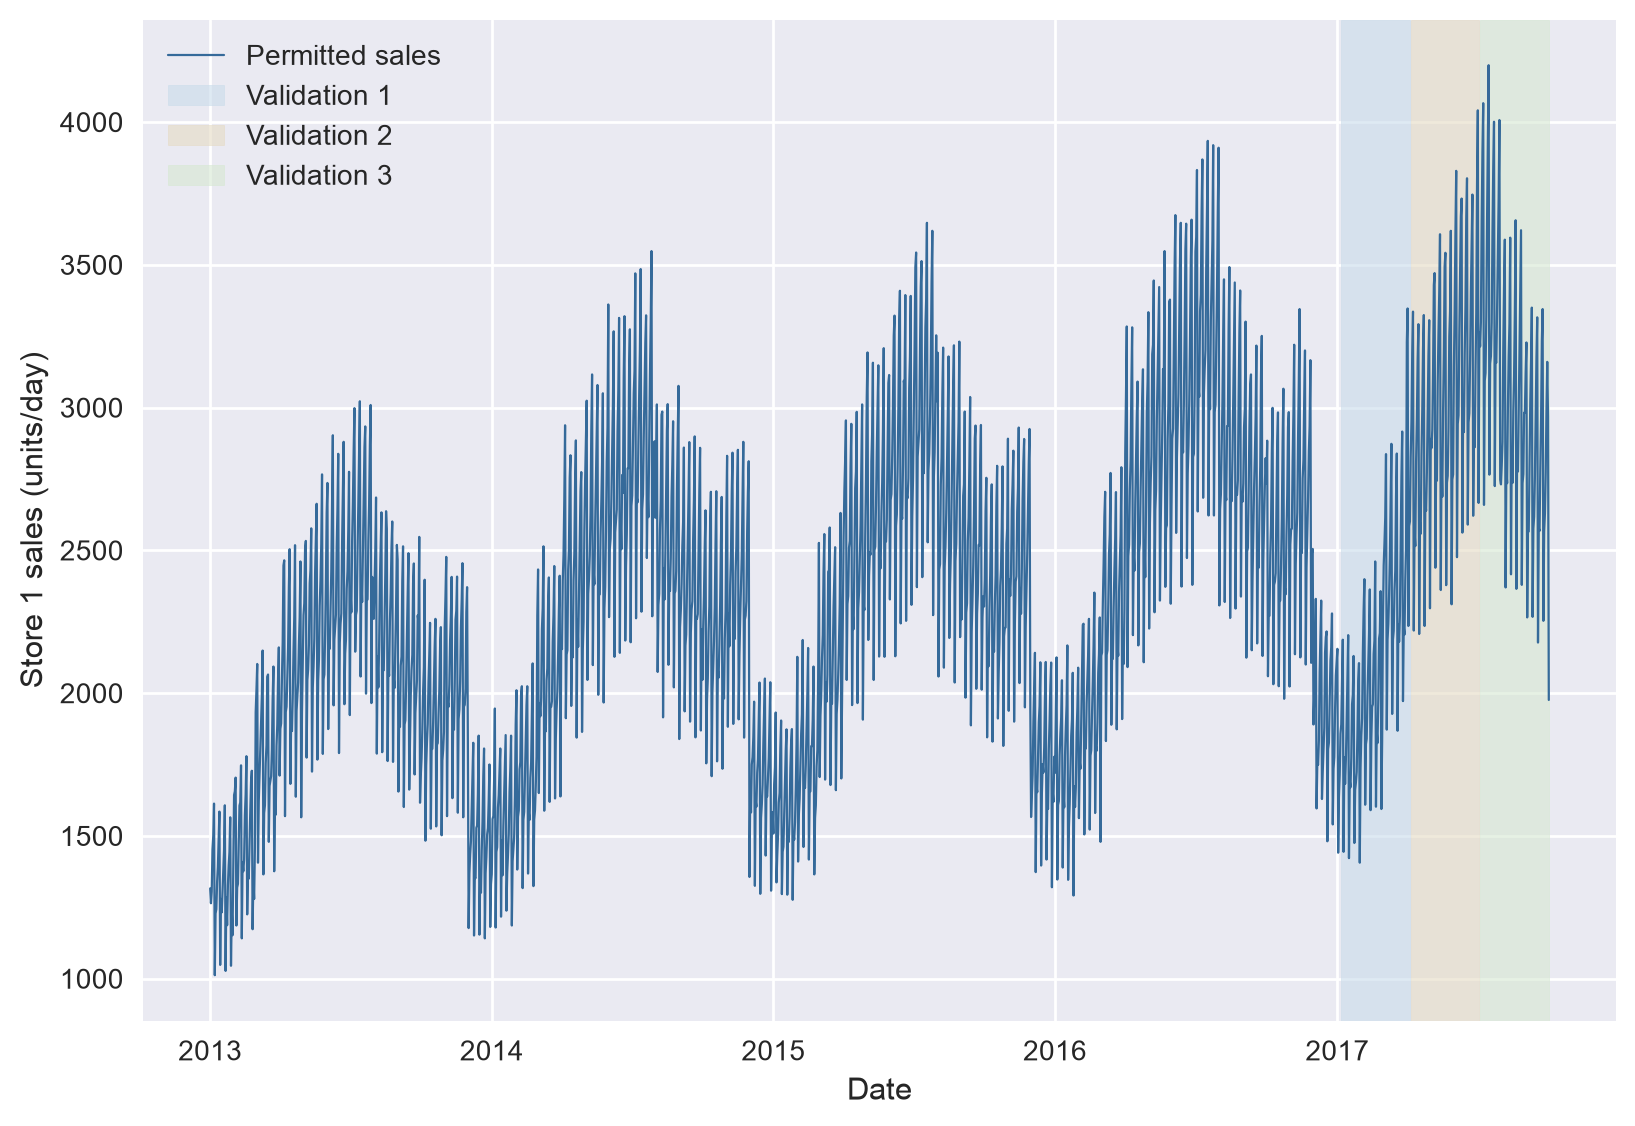

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '01',
 'type': 'graph',
 'filename': 'graphs/atsf04_graph_01.png',
 'section': 'Future behind a boundary',
 'title': 'Store 1 before the forecast origin',
 'caption': 'Permitted daily sales for store 1; shading marks the three 90-day validation blocks. No final outcomes are shown.',
 'alt_text': 'Graph 01: Store 1 before the forecast origin. Permitted daily sales for store 1; shading marks the three 90-day validation blocks. No final outcomes are shown.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_graph_01.json',
 'sidecar_sha256': '5a6fa9895abb324b97c2072eadb12c24532c1b69f65c747f740fd73944d78963',
 'png_sha256': '83c813b76c0efcc2b8b5b2e9de435df5f1f605cb3e5db7b48ab86c33f548e51a',
 'source_result_sha256': 'fbf87a876bf22b39c0e4eb1b4a3fd5f2dd1e9174b7bec2b100d69d44f0351b3f',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa603899a3e9da7c',
 'execution_started_at':

In [9]:
make_visual(1, panel, capture, result, tests)

*Graph 01. Permitted daily sales for store 1; shading marks the three 90-day validation blocks. No final outcomes are shown.*

Store 1 has weekly oscillation within an annual envelope; the three shaded validation blocks cover distinct parts of that envelope. All ten stores remain in the cohort.

# Give the planner a contract

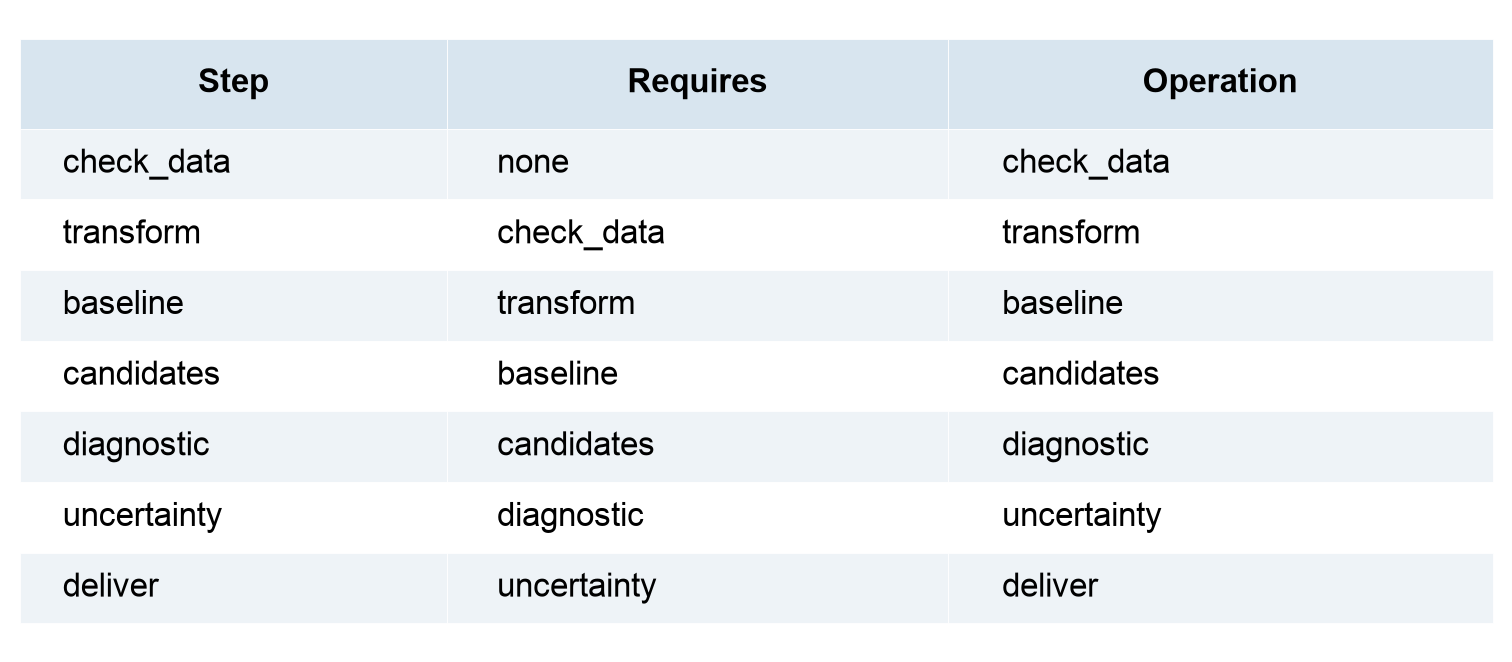

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '02',
 'type': 'table',
 'filename': 'graphs/atsf04_table_02.png',
 'section': 'Give the planner a contract',
 'title': 'The initial executable plan',
 'caption': 'The genuine initial plan, including each prerequisite. Transformation and other settings are recorded in the full plan.',
 'alt_text': 'Table 02: The initial executable plan. The genuine initial plan, including each prerequisite. Transformation and other settings are recorded in the full plan.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_02.json',
 'sidecar_sha256': 'c4f2e731bc5558c9af84bd7eeaf201036e11fff27ddcf2a0dd5d985d860dad73',
 'png_sha256': 'b3f867c65ddf3e1e07550eb8ec2683312681af1e5826cd2544eb6d6636ea0758',
 'source_result_sha256': '23274da861c080851feab86691a094a120e0b2f75f9aeba67af42306f5504924',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa603899a3e9da7c',
 'execution_started_at'

In [10]:
make_visual(2, panel, capture, result, tests)

*Table 02. The genuine initial plan, including each prerequisite. Transformation and other settings are recorded in the full plan.*

The genuine planner chose identity scale and the assigned trend candidate. It did not explain the transformation choice specifically. Its graph is prescribed; meaningful free decisions here are transformation and repair candidate subset.

# Execute

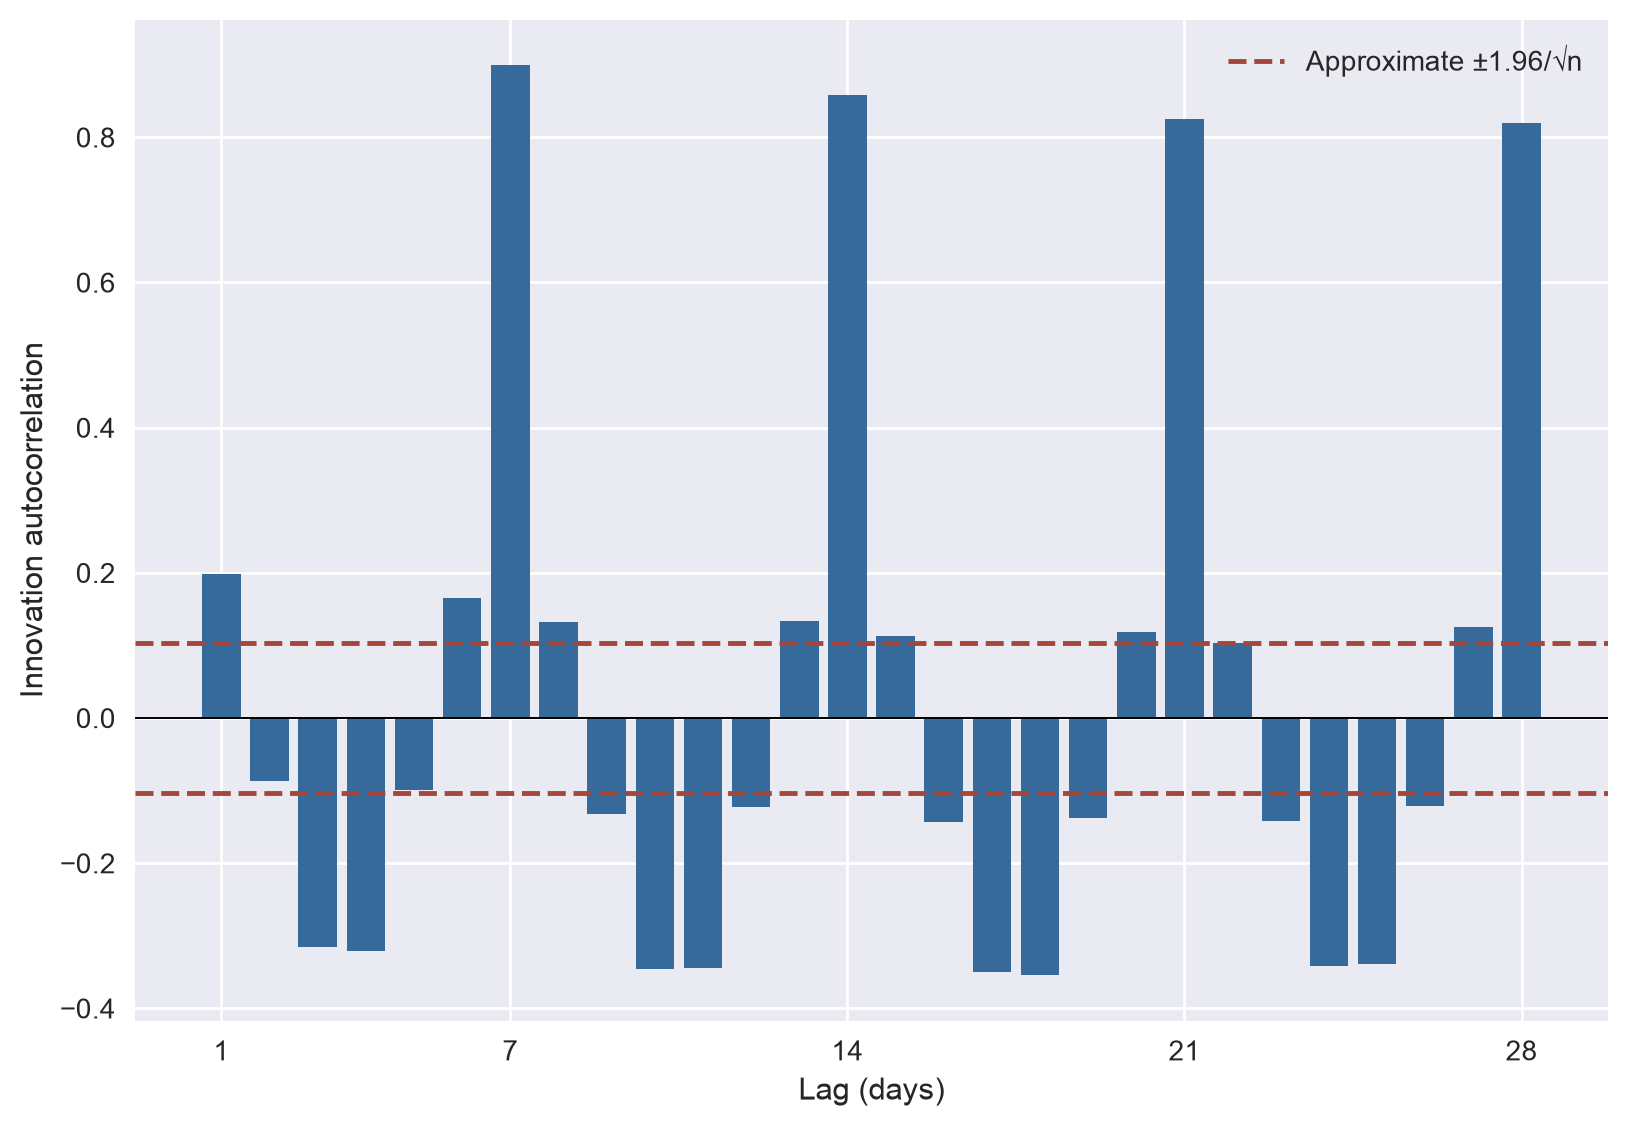

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '03',
 'type': 'graph',
 'filename': 'graphs/atsf04_graph_03.png',
 'section': 'Execute',
 'title': 'What the trend model leaves behind',
 'caption': 'Store 1 standardized one-step innovation autocorrelations over the last 364 permitted days. The dashed bounds are descriptive approximations.',
 'alt_text': 'Graph 03: What the trend model leaves behind. Store 1 standardized one-step innovation autocorrelations over the last 364 permitted days. The dashed bounds are descriptive approximations.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_graph_03.json',
 'sidecar_sha256': 'ae6623a431bf7ec3836440bbd46325323ab629578de237ef8a1cec1b86f2fac0',
 'png_sha256': 'de3d5f6407f18a87603a6fed400f115a688a0768f8c75516427909ed93cdb2f8',
 'source_result_sha256': '2ff62ce96ea404b388cfe2ec72844b4d87d3856da28c861c3c0c180b6ad6a40d',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa60

In [11]:
make_visual(3, panel, capture, result, tests)

*Graph 03. Store 1 standardized one-step innovation autocorrelations over the last 364 permitted days. The dashed bounds are descriptive approximations.*

Store 1's trend residual ACF7 is 0.899. All ten trend checks fail; some p-values underflow to floating-point zero. Weekly-lag dependence motivates a seasonal hypothesis, while Ljung–Box does not identify its cause.

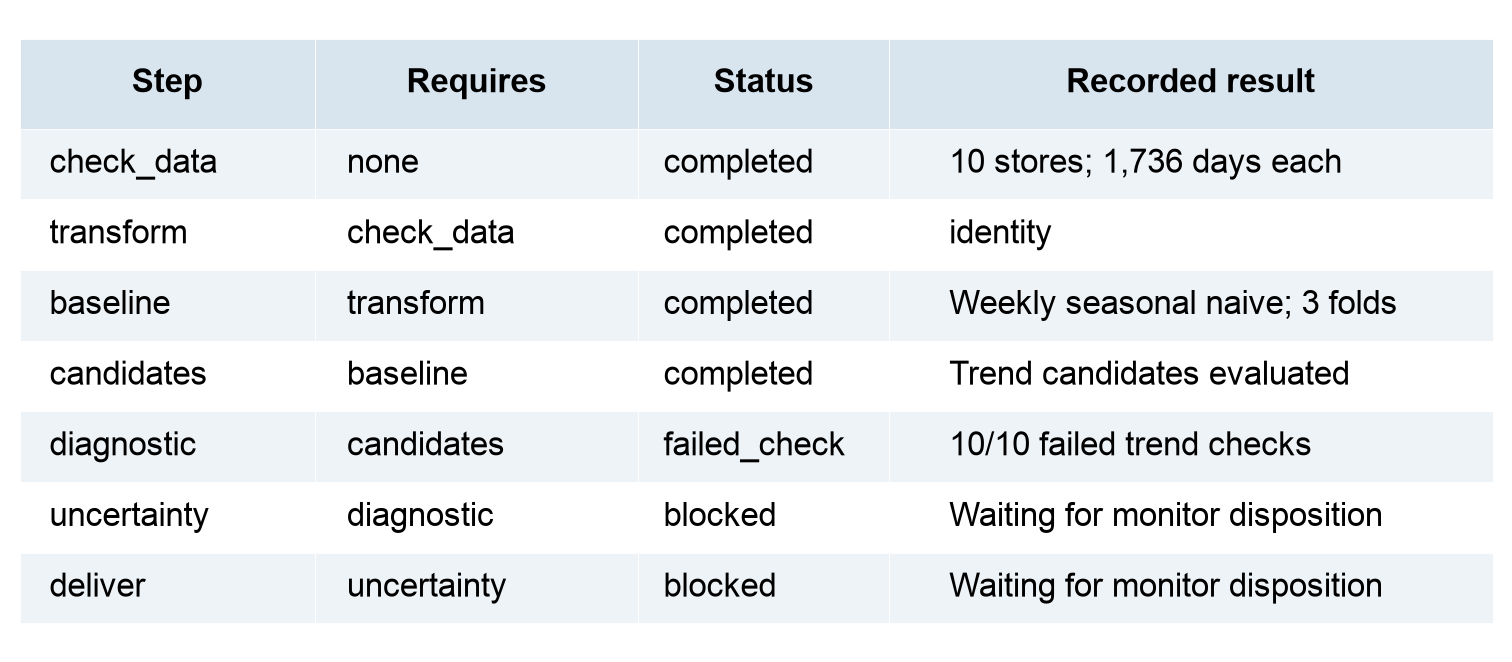

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '04',
 'type': 'table',
 'filename': 'graphs/atsf04_table_04.png',
 'section': 'Execute',
 'title': 'Execution pauses at the failed check',
 'caption': 'Initial shared-plan status before revision. The monitor tests the trend candidate, independently of validation selection.',
 'alt_text': 'Table 04: Execution pauses at the failed check. Initial shared-plan status before revision. The monitor tests the trend candidate, independently of validation selection.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_04.json',
 'sidecar_sha256': '7e47d4848c33c62eeb684576ca2febe3f3ec16a72d9427728fde465a3bc76311',
 'png_sha256': 'e430ca39162a8d239ef30816ae24e2ba46a0ec689884bdd824845931c88ee4b3',
 'source_result_sha256': '5a1da39fb7a221eec29aec18e98e76a937ac95144b42ae2f68e7cf38e7a72f78',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa603899a3e9da7c',
 'execution_started_a

In [12]:
make_visual(4, panel, capture, result, tests)

*Table 04. Initial shared-plan status before revision. The monitor tests the trend candidate, independently of validation selection.*

All ten initial validation selections are seasonal naive. The failed checks concern the trend candidates, not those selected baselines. Completed work is retained and two pending steps are blocked.

# Revise the work


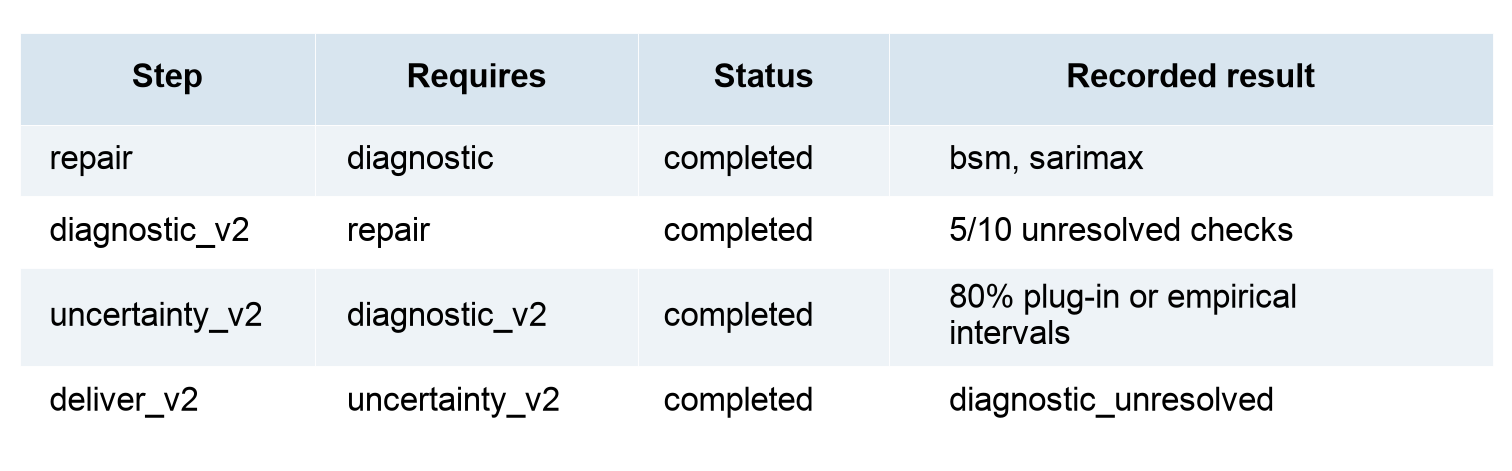

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '05',
 'type': 'table',
 'filename': 'graphs/atsf04_table_05.png',
 'section': 'Revise the work',
 'title': 'The revised suffix and its outcome',
 'caption': 'The accepted revision replaces pending work and retains the completed prefix and failed event. Full per-store monitor values are archived.',
 'alt_text': 'Table 05: The revised suffix and its outcome. The accepted revision replaces pending work and retains the completed prefix and failed event. Full per-store monitor values are archived.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_05.json',
 'sidecar_sha256': '3b044d129c4ac4646afd661d4bc0e5d88a39b1ea028a00aa73fa0a00aed9a218',
 'png_sha256': '64b7d866085d1041087398d6de5f07bb710cb5fe3622f5f408dbfd37263f65d3',
 'source_result_sha256': '10d02e2f2f9799bd2622e9b3898d09eb14135cebd670fa003ef4ed01843b282a',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa

In [13]:
make_visual(5, panel, capture, result, tests)

*Table 05. The accepted revision replaces pending work and retains the completed prefix and failed event. Full per-store monitor values are archived.*

The genuine revision retains identity scale and adds both BSM and SARIMAX. Validation selects SARIMAX in eight stores and BSM in two. Stores 1/2/3/4/7 pass the repeated check; the other five fail, so the shared controller is diagnostic_unresolved despite ten deliveries. Twenty existing baseline/trend artifacts are reused; the original failed event remains and blocked steps become superseded. The author audit finds 4/6 factual propositions supported and 2 ambiguous, with one proposal excluded; the singular p-value and inferred cause are ambiguous.

# Freeze, then open

In [14]:
result = score_study(panel, capture, run_dir)
print(pd.DataFrame(result['summaries']).drop(columns='eligible_cases').to_string(index=False))

           arm  delivered  denominator       rmse        mae     mase  coverage       width  interval_score
seasonal_naive         10           10 518.673634 376.218889 3.479950  0.693333 1234.960000     1978.691111
  initial_plan         10           10 518.673634 376.218889 3.479950  0.693333 1234.960000     1978.691111
    agent_plan         10           10 342.552517 259.805104 2.380485  0.766667  953.956251     1228.846570
     fixed_bsm         10           10 518.673634 376.218889 3.479950  0.693333 1234.960000     1978.691111


The printed rows retain coverage out of all ten stores. Pooled RMSE/MAE use equally long store-day forecasts; MASE is averaged equally across stores. Paired conclusions require the same delivered stores in both arms. Undefined metrics or missing predictions retain explicit reasons.

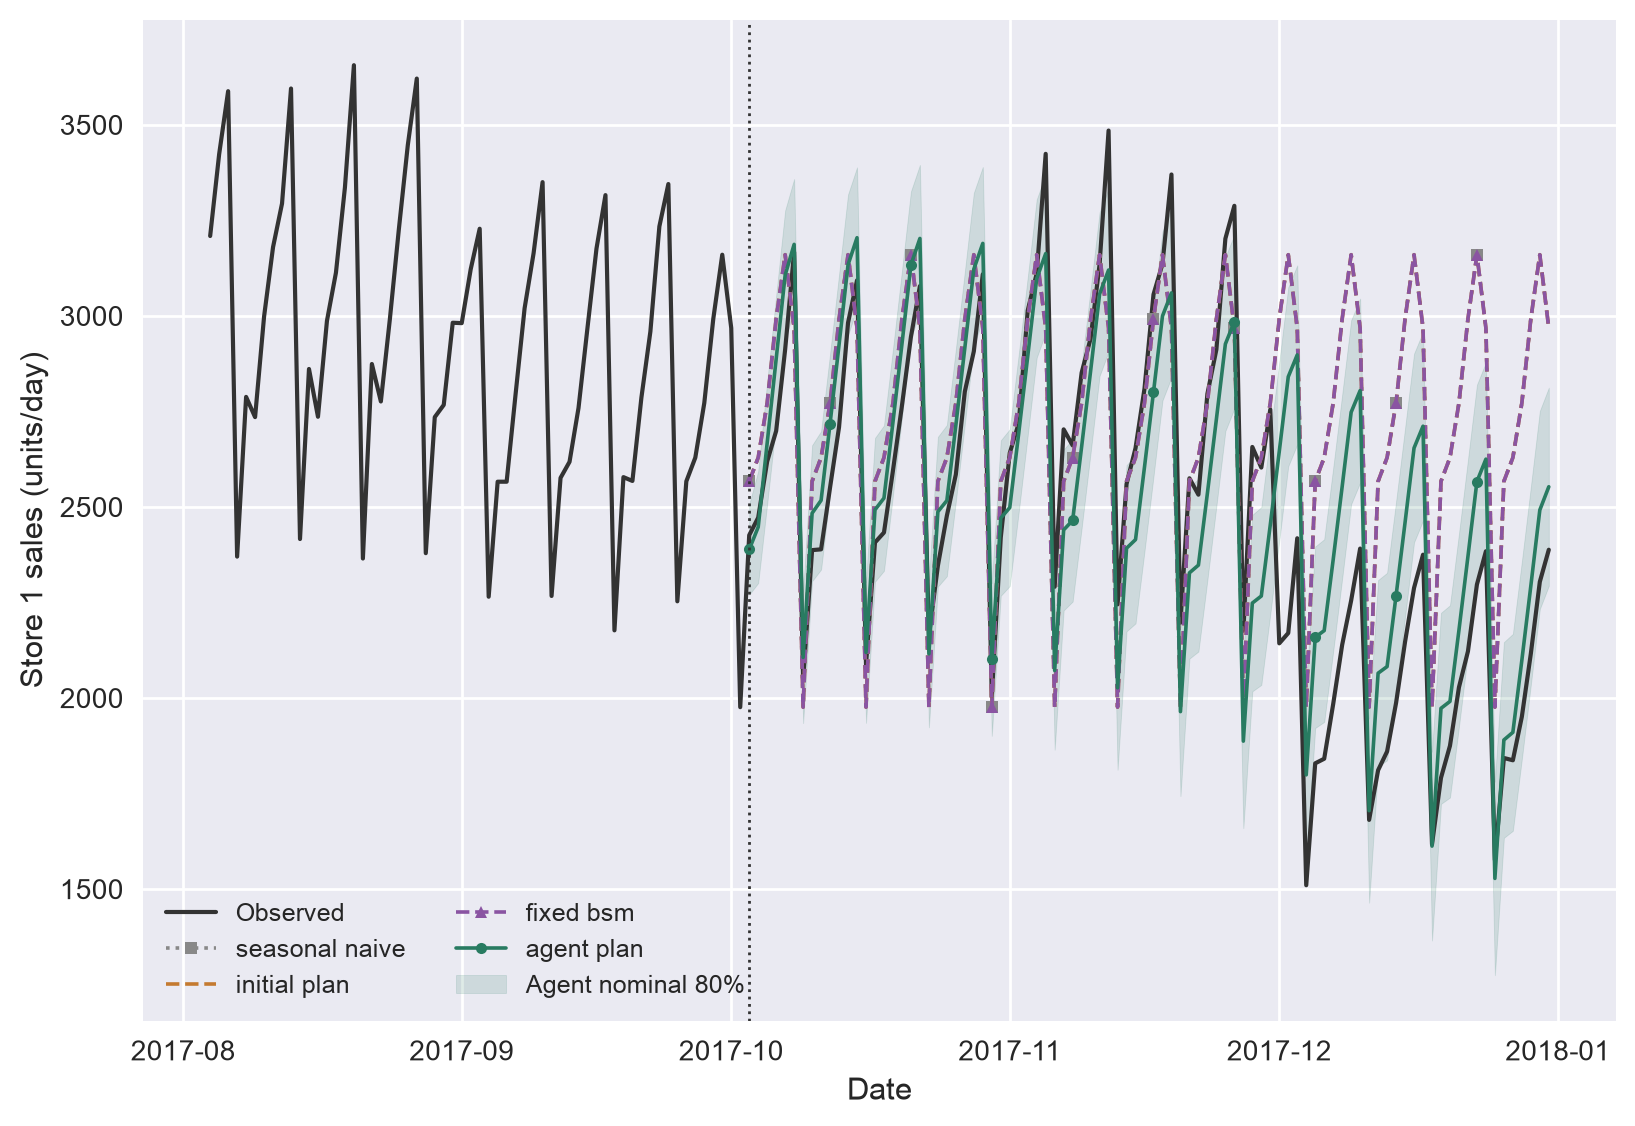

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '06',
 'type': 'graph',
 'filename': 'graphs/atsf04_graph_06.png',
 'section': 'Freeze, then open',
 'title': 'Ninety days after the forecast freeze',
 'caption': "Predeclared store 1: frozen point forecasts and the agent's nominal 80% marginal interval against the final 90 daily outcomes.",
 'alt_text': "Graph 06: Ninety days after the forecast freeze. Predeclared store 1: frozen point forecasts and the agent's nominal 80% marginal interval against the final 90 daily outcomes.",
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_graph_06.json',
 'sidecar_sha256': '6f550f417ddbc7fa81775d7ae019a05e76043078e3f65fbd3b6044858a245070',
 'png_sha256': '26075a93202af49a66364040a5369b3438dd5065e716e3867adaaf8b34168621',
 'source_result_sha256': 'a048684efdf03f07d7721390906643eb8377cc34e76eea3490f885bb51cbf7b3',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa603899a3e9da7c',

In [15]:
make_visual(6, panel, capture, result, tests)

*Graph 06. Predeclared store 1: frozen point forecasts and the agent's nominal 80% marginal interval against the final 90 daily outcomes.*

Store 1 agent RMSE is 235.9 versus 461.8 for seasonal naive; the initial and fixed selections coincide with that naive line. Agent interval coverage is only 58.9% here, despite lower point error.

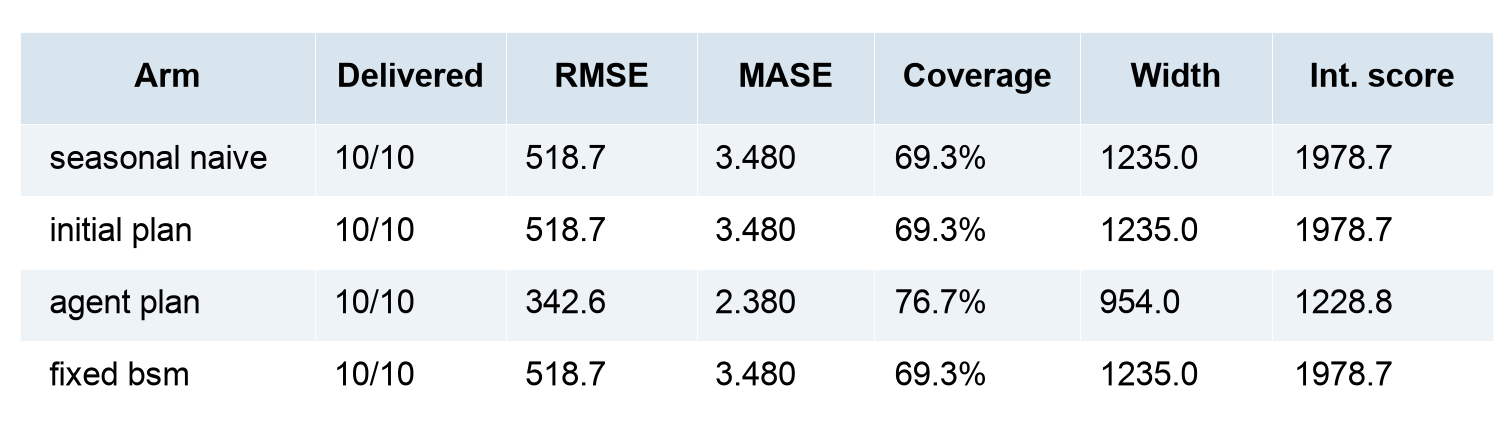

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '07',
 'type': 'table',
 'filename': 'graphs/atsf04_table_07.png',
 'section': 'Freeze, then open',
 'title': 'Forecast error and uncertainty across ten stores',
 'caption': 'All four arms: delivery counts out of ten, pooled daily RMSE, equal-store mean MASE, and mean interval diagnostics over delivered cases. Full 40-row scores retain individual statuses and MAE.',
 'alt_text': 'Table 07: Forecast error and uncertainty across ten stores. All four arms: delivery counts out of ten, pooled daily RMSE, equal-store mean MASE, and mean interval diagnostics over delivered cases. Full 40-row scores retain individual statuses and MAE.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_07.json',
 'sidecar_sha256': 'b69156981f4201bf98612cd4d93b498dc0e779745ab42922e6d825e421bd3e21',
 'png_sha256': '405fc8bc5edf78d4e0ef3e4ef7b3c7e24b1c1b60a8c2bfb9e955ce3af2f9feb7',
 'source_result_sha256': 'b1348026

In [16]:
make_visual(7, panel, capture, result, tests)

*Table 07. All four arms: delivery counts out of ten, pooled daily RMSE, equal-store mean MASE, and mean interval diagnostics over delivered cases. Full 40-row scores retain individual statuses and MAE.*

All four arms deliver10/10 cases. Agent pooled RMSE is 342.6 versus 518.7, and mean MASE is 2.38 versus 3.48. Agent RMSE is lower in nine stores; store 3 loses709.3 versus 557.7. Fixed log BSM loses validation in eight stores and fails convergence in two, selecting naive everywhere. The comparison changes transformation and menu, so it cannot isolate LLM-planning benefit. Agent mean coverage76.7%, width954.0 and interval score1228.8 improve on naive69.3%,1235.0 and 1978.7, but do not establish calibrated uncertainty across dependent stores/days.

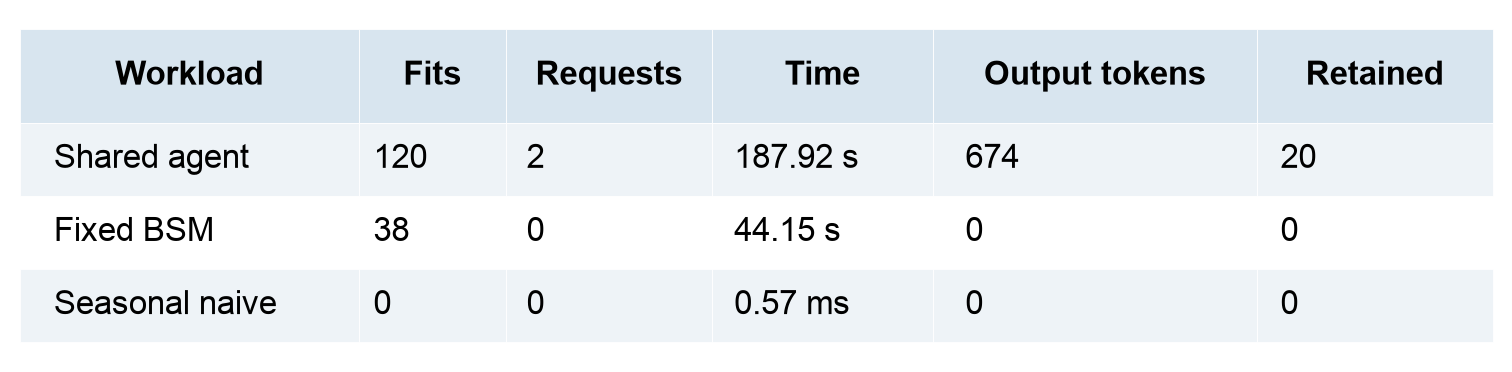

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '08',
 'type': 'table',
 'filename': 'graphs/atsf04_table_08.png',
 'section': 'Freeze, then open',
 'title': 'Actual work in the genuine run',
 'caption': 'Original measured agent and comparator workloads, excluding synthetic development and publication export. Retained artifacts are logical reuse, not new fits.',
 'alt_text': 'Table 08: Actual work in the genuine run. Original measured agent and comparator workloads, excluding synthetic development and publication export. Retained artifacts are logical reuse, not new fits.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_08.json',
 'sidecar_sha256': '101813a710dad8cde0210087bfacf28833ab725f68b3e8fa860a9e2c5681a004',
 'png_sha256': '89abeb2e1661d85d8a411751ffa46ab63f404b0becaf5bb43237dbd438df57ef',
 'source_result_sha256': '8a5fbbacf2dffdf2c94380abc6393cef118cfd245abfc921b7fb7c6bc9e0d153',
 'source_capture_sha256': '6e25ccd2e24d7b8209

In [17]:
make_visual(8, panel, capture, result, tests)

*Table 08. Original measured agent and comparator workloads, excluding synthetic development and publication export. Retained artifacts are logical reuse, not new fits.*

The original agent workload takes 187.92s, with 2 model requests,120 fits and 674 output tokens. Fixed BSM takes 44.15s and 38 fit attempts, including two failures. Baseline time is 0.57ms, not zero. No-repair shares the initial prefix and has no independent runtime. The workload differs, so this is not an efficiency comparison against an equivalent search.

# Control the controller

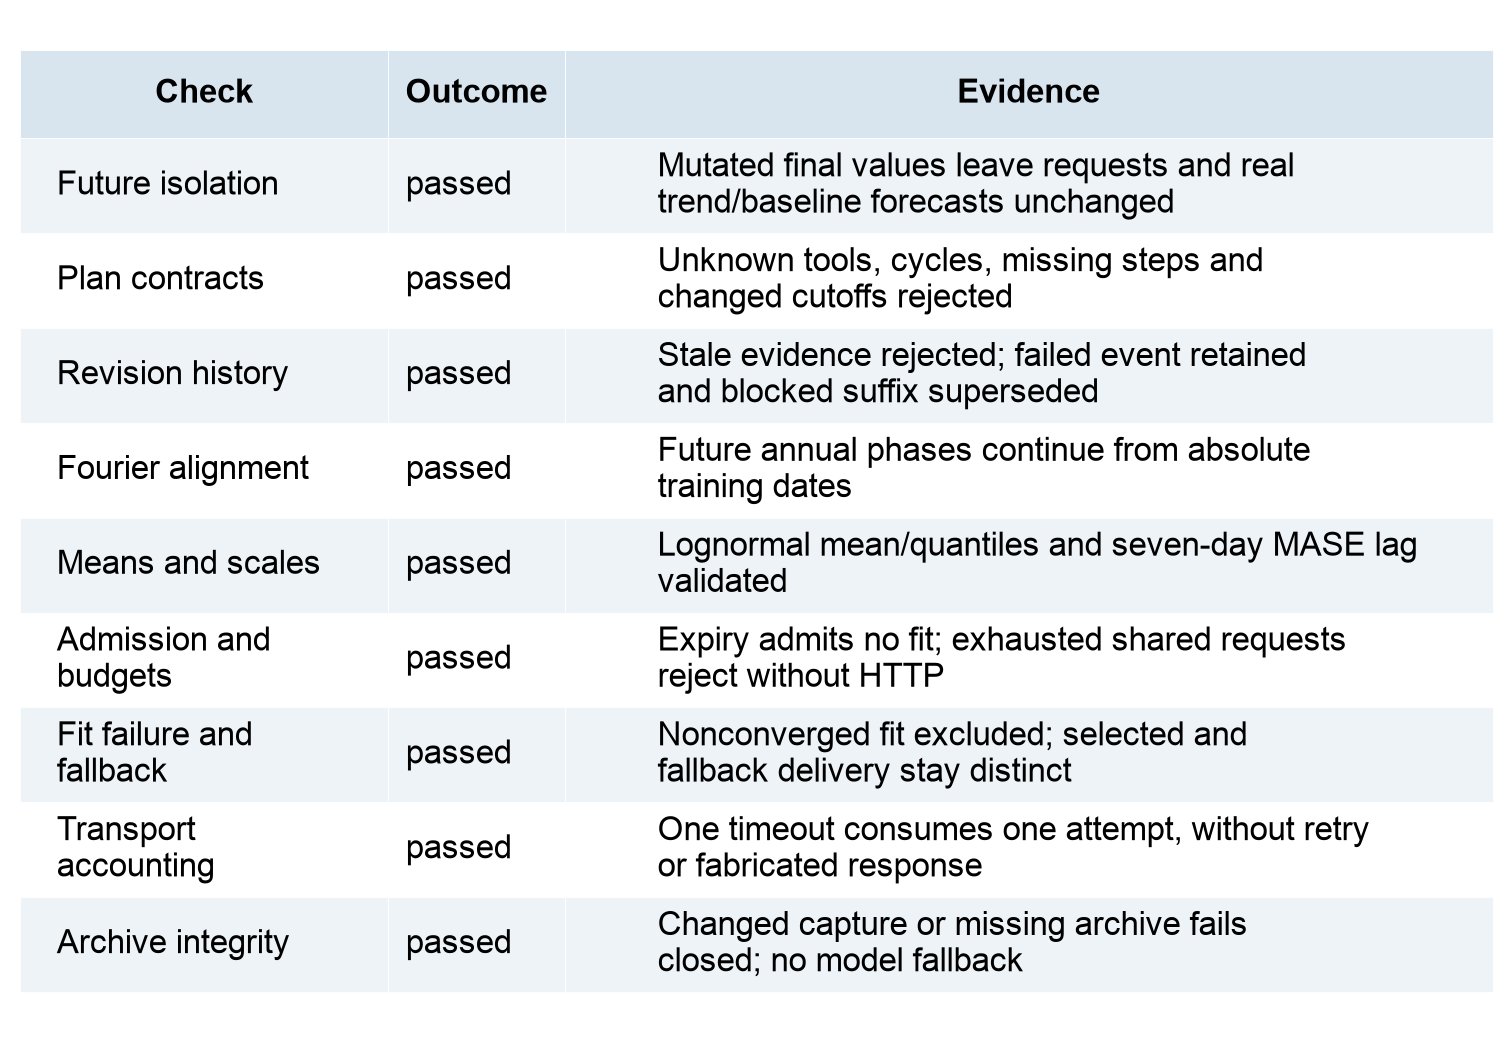

{'episode_number': 4,
 'asset_prefix': 'atsf04_',
 'visual_number': '09',
 'type': 'table',
 'filename': 'graphs/atsf04_table_09.png',
 'section': 'Control the controller',
 'title': 'Software checks outside the live cohort',
 'caption': 'Deterministic and numerical development checks. These do not estimate live model failure probabilities.',
 'alt_text': 'Table 09: Software checks outside the live cohort. Deterministic and numerical development checks. These do not estimate live model failure probabilities.',
 'sidecar': 'examples/module04/exports/export-20261117T001742916751/atsf04_table_09.json',
 'sidecar_sha256': '9a3761841232713dbea5f5fac6510fed96c34154b9e8fede094b99fe95f29fe0',
 'png_sha256': '8dffad31ca243400dfd14fb165b0af67599a357a2e167f83f52b0256618e0389',
 'source_result_sha256': '573afe04da9a75e17555742326ab7fb6e347f9c233d50c9a2a1cedde5f204ce1',
 'source_capture_sha256': '6e25ccd2e24d7b82098baf53c48e37aef9c3e00c4c375232fa603899a3e9da7c',
 'execution_started_at': '2026-11-17

In [18]:
make_visual(9, panel, capture, result, tests)

*Table 09. Deterministic and numerical development checks. These do not estimate live model failure probabilities.*

All nine development checks pass, outside genuine-agent denominators. Fresh-kernel analysis-only replay also passed with model/network sockets blocked; it verifies frozen analysis and does not recompute numerical tools or decisions.